# Лабораторна робота №3

**Варіант 3.** Припускаючи нормальні розподіли, перевірити гіпотезу про те, що середні втрати на день «ббм» збігаються з втратами «танків», домноженими на 2. У статистиці дано суму, розмір вибірки - кількість днів війни. Вважати, що $\sigma_1^2=100$, $\sigma_2^2=50$.

Дані взято з відкритого набору [2022-Ukraine-Russia-War-Dataset](https://github.com/PetroIvaniuk/2022-Ukraine-Russia-War-Dataset) (файл `russia_losses_equipment.json`, джерело - Генштаб ЗСУ). Це накопичувальна статистика: кожен рядок містить загальні втрати з початку війни на відповідну дату. «ббм» - це поле `APC`, «танки» - поле `tank`.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

with open("russia_losses_equipment.json", encoding="utf-8") as f:
    losses = pd.DataFrame(json.load(f))

last = losses.iloc[-1]
n = int(last["day"])
sum_bbm = int(last["APC"])
sum_tank = int(last["tank"])

print("остання дата:", last["date"])
print("кількість днів війни n =", n)
print("сумарні втрати ббм:   ", sum_bbm)
print("сумарні втрати танків:", sum_tank)
losses[["date", "day", "APC", "tank"]].tail()

остання дата: 2026-10-30
кількість днів війни n = 1710
сумарні втрати ббм:    25617
сумарні втрати танків: 12450


,date,day,APC,tank
1704,2026-10-26,1706,25609,12448
1705,2026-10-27,1707,25609,12448
1706,2026-10-28,1708,25609,12448
1707,2026-10-29,1709,25614,12449
1708,2026-10-30,1710,25617,12450


## 1. Постановка задачі

Нехай $X_1,\dots,X_n$ - втрати ббм за кожен день, $Y_1,\dots,Y_n$ - втрати танків за кожен день, $n$ - кількість днів війни. Припускаємо
$$X_i\sim N(\mu_1,\ \sigma_1^2),\qquad Y_i\sim N(\mu_2,\ \sigma_2^2),\qquad \sigma_1^2=100,\ \ \sigma_2^2=50,$$
вибірки незалежні. Середні втрати на день - це $\mu_1$ та $\mu_2$. Перевіряємо
$$H_0:\ \mu_1=2\mu_2\qquad\text{проти}\qquad H_1:\ \mu_1\ne2\mu_2 .$$

У статистиці є лише суми $\sum X_i$ та $\sum Y_i$, але для тесту окремі дні не потрібні, достатньо вибіркових середніх
$$\bar X=\frac1n\sum_{i=1}^nX_i,\qquad \bar Y=\frac1n\sum_{i=1}^nY_i .$$

In [2]:
x_mean = sum_bbm / n
y_mean = sum_tank / n

print("середні втрати ббм на день:    ", round(x_mean, 4))
print("середні втрати танків на день: ", round(y_mean, 4))
print("2 * середні втрати танків:     ", round(2 * y_mean, 4))

середні втрати ббм на день:     14.9807
середні втрати танків на день:  7.2807
2 * середні втрати танків:      14.5614


## 2. Статистика критерію

$\bar X\sim N(\mu_1,\sigma_1^2/n)$, $\bar Y\sim N(\mu_2,\sigma_2^2/n)$ незалежні, а $D(2\bar Y)=4D\bar Y$, тому $\bar X-2\bar Y\sim N\!\left(\mu_1-2\mu_2,\ \frac{\sigma_1^2+4\sigma_2^2}{n}\right)$. За $H_0$ середнє дорівнює нулю, отже
$$Z=\frac{\bar X-2\bar Y}{\sqrt{(\sigma_1^2+4\sigma_2^2)/n}}\ \sim\ N(0,1).$$
Гіпотезу відхиляємо, якщо $|Z|>z_{1-\alpha/2}$.  Для $\alpha=0.05$ це $1.96$, для $\alpha=0.01$ - $2.576$. Також рахуємо $p=2\,(1-\Phi(|Z|))$.

In [3]:
sigma1_sq = 100
sigma2_sq = 50

diff = x_mean - 2 * y_mean
se = np.sqrt((sigma1_sq + 4 * sigma2_sq) / n)
z = diff / se
p_value = 2 * (1 - norm.cdf(abs(z)))

print("X - 2Y =", round(diff, 4))
print("SE     =", round(se, 4))
print("Z      =", round(z, 4))
print("p-value =", round(p_value, 4))

for alpha in (0.05, 0.01):
    z_crit = norm.ppf(1 - alpha / 2)
    verdict = "відхиляємо H0" if abs(z) > z_crit else "H0 не відхиляємо"
    print(f"рівень {alpha}: критичне значення {z_crit:.3f}, |Z| = {abs(z):.3f} -> {verdict}")

X - 2Y = 0.4193
SE     = 0.4189
Z      = 1.0011
p-value = 0.3168
рівень 0.05: критичне значення 1.960, |Z| = 1.001 -> H0 не відхиляємо
рівень 0.01: критичне значення 2.576, |Z| = 1.001 -> H0 не відхиляємо


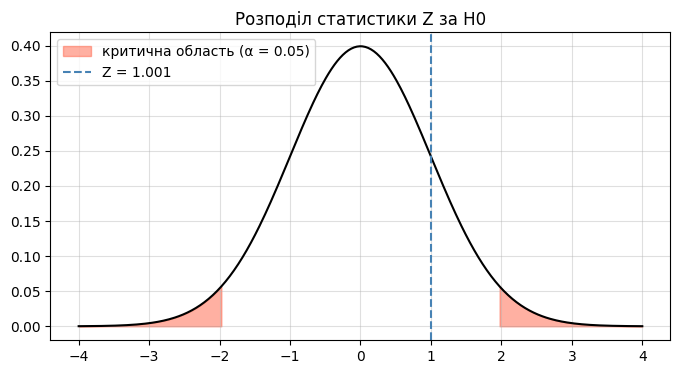

In [4]:
grid = np.linspace(-4, 4, 400)
z_crit = norm.ppf(0.975)

plt.figure(figsize=(8, 4))
plt.plot(grid, norm.pdf(grid), "k")
plt.fill_between(grid, norm.pdf(grid), where=(grid <= -z_crit), color="tomato", alpha=0.5, label="критична область (α = 0.05)")
plt.fill_between(grid, norm.pdf(grid), where=(grid >= z_crit), color="tomato", alpha=0.5)
plt.axvline(z, color="steelblue", linestyle="--", label=f"Z = {z:.3f}")
plt.title("Розподіл статистики Z за H0")
plt.legend()
plt.grid(alpha=0.4)
plt.show()

## 3. Довірчий інтервал для $\mu_1-2\mu_2$

Статистика $Z$ з п. 2 нормальна, тож довірчий інтервал рівня $1-\alpha$ має вигляд
$$(\bar X-2\bar Y)\pm z_{1-\alpha/2}\sqrt{\frac{\sigma_1^2+4\sigma_2^2}{n}} .$$
Тест відхиляє $H_0$ тоді й лише тоді, коли $0$ не потрапляє в цей інтервал.

In [5]:
for level in (0.95, 0.99):
    q = norm.ppf(1 - (1 - level) / 2)
    print(f"рівень {level}: від {diff - q * se:.4f} до {diff + q * se:.4f}")

рівень 0.95: від -0.4016 до 1.2402
рівень 0.99: від -0.6596 до 1.4982


## 4. Висновок

Середні втрати ббм на день - $\bar X\approx14.98$, подвоєні середні втрати танків - $2\bar Y\approx14.56$. Різниця $0.42$ майже дорівнює своїй стандартній похибці $0.42$, тому $Z\approx1.00$, $p\approx0.32$. Це менше за $1.96$ і $2.576$, тож на рівнях 0.05 та 0.01 гіпотезу $H_0:\mu_1=2\mu_2$ не відхиляємо. Інтервали для $\mu_1-2\mu_2$ - $[-0.40;\ 1.24]$ та $[-0.66;\ 1.50]$ - містять нуль.

Тобто ббм втрачають приблизно вдвічі більше, ніж танків, і такий розкид між $\bar X$ та $2\bar Y$ цілком можливий випадково. Це не доводить, що рівність точна, а лише те, що дані їй не суперечать.